In [3]:
import sys, os
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns

ROOT = os.path.abspath("..")                 # repo folder, one level up from notebooks/
sys.path.append(ROOT)
DATA = os.path.join(ROOT, "data", "processed", "loans_clean.parquet")
FIG = os.path.join(ROOT, "reports", "figures")

df = pd.read_parquet(DATA)
print(df.shape)

def save(name):
    plt.savefig(os.path.join(FIG, name), dpi=150, bbox_inches="tight")
    plt.show()

(86141, 71)


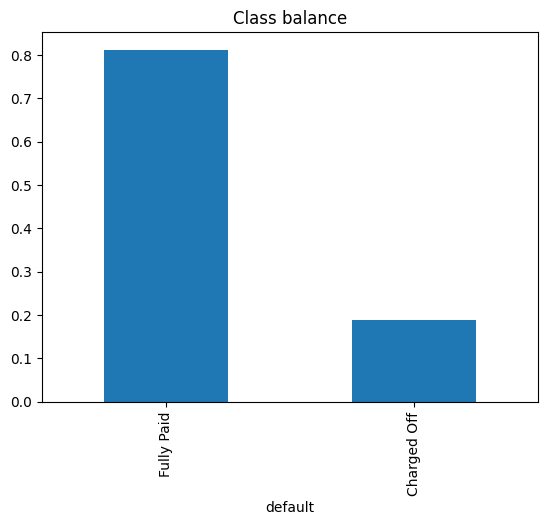

In [4]:
df["default"].value_counts(normalize=True).rename({0: "Fully Paid", 1: "Charged Off"}).plot.bar()
plt.title("Class balance")
save("class_balance.png")

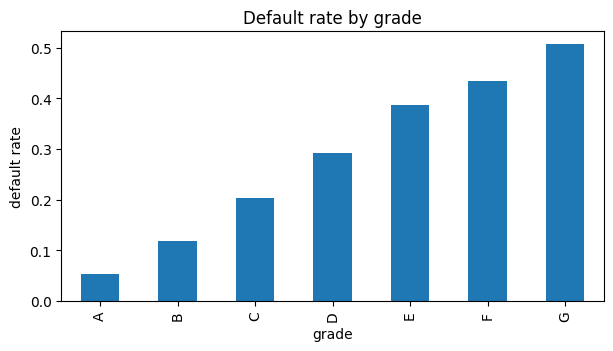

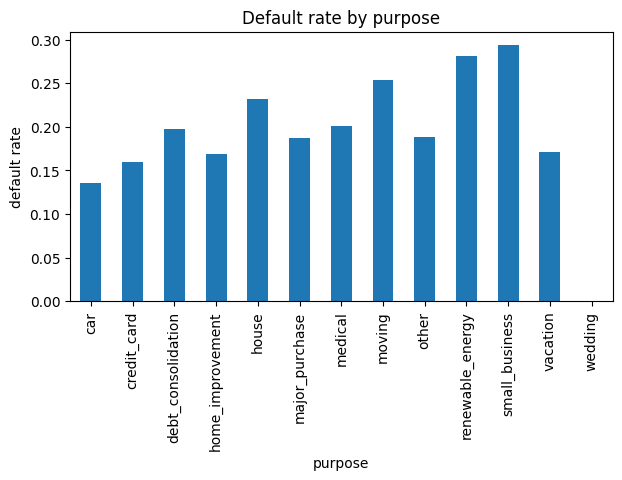

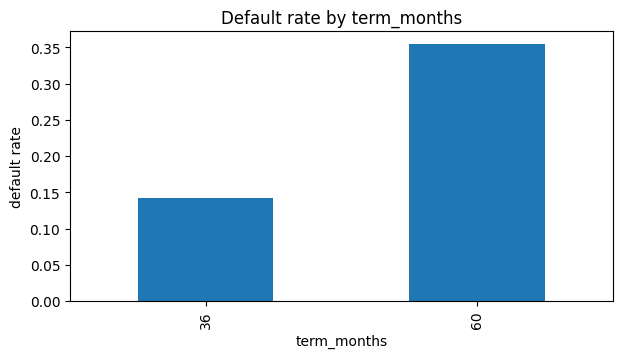

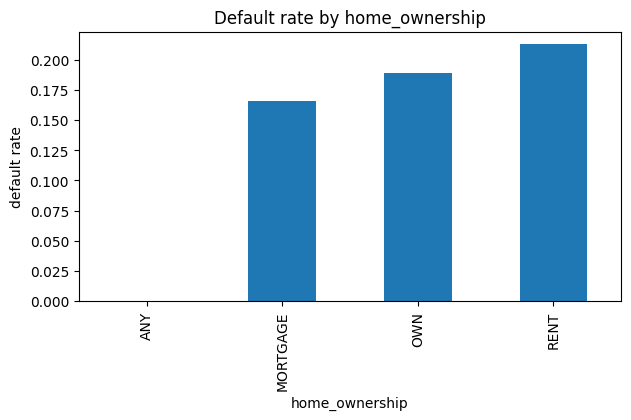

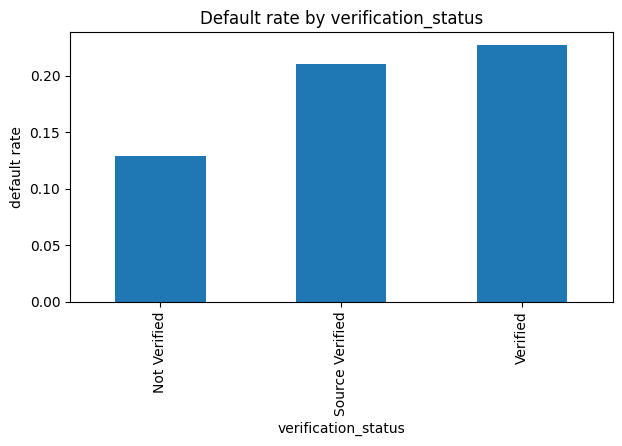

In [5]:
for col in ["grade", "purpose", "term_months", "home_ownership", "verification_status"]:
    df.groupby(col)["default"].mean().sort_index().plot.bar(figsize=(7, 3.5))
    plt.ylabel("default rate")
    plt.title(f"Default rate by {col}")
    save(f"default_by_{col}.png")

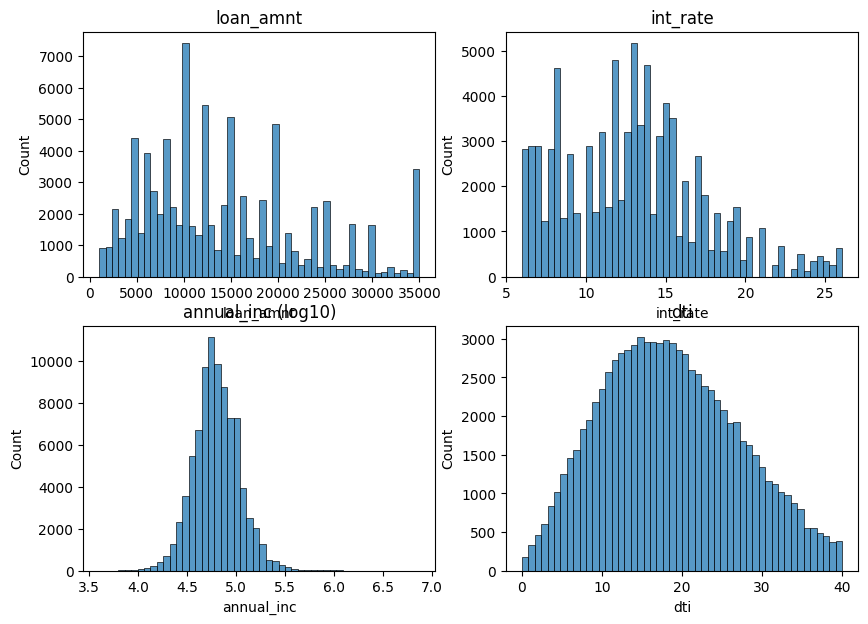

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(10, 7))
for a, c in zip(ax.ravel(), ["loan_amnt", "int_rate", "annual_inc", "dti"]):
    s = df[c].dropna()
    if c == "annual_inc":
        s = np.log10(s[s > 0])
    if c == "dti":
        s = s[s.between(0, 60)]
    sns.histplot(s, bins=50, ax=a)
    a.set_title(c + (" (log10)" if c == "annual_inc" else ""))
save("distributions.png")

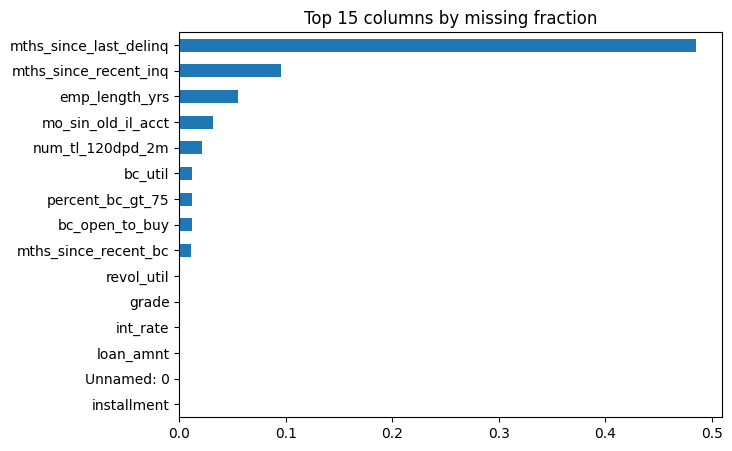

In [7]:
miss = df.isna().mean().sort_values(ascending=False).head(15)
miss.plot.barh(figsize=(7, 5))
plt.gca().invert_yaxis()
plt.title("Top 15 columns by missing fraction")
save("missing_top15.png")

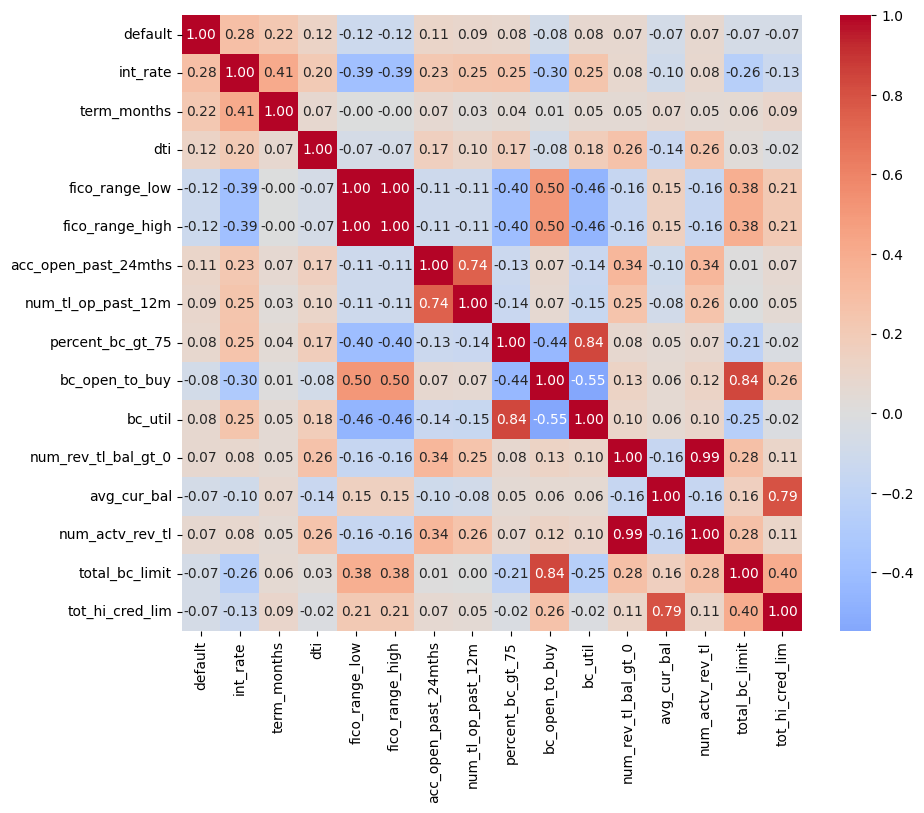

In [8]:
num = df.select_dtypes("number").drop(columns=["issue_year"], errors="ignore")
top = num.corr()["default"].abs().sort_values(ascending=False).head(16).index
plt.figure(figsize=(10, 8))
sns.heatmap(num[top].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
save("correlations.png")